In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('./freshbite_marketing_data.csv')
df.head()

,date,tv_spend,search_spend,social_spend,display_spend,price_index,promotion,distribution,holiday,tv_adstock_true,search_adstock_true,social_adstock_true,display_adstock_true,tv_contribution_true,search_contribution_true,social_contribution_true,display_contribution_true,revenue
0,2023-01-02,45288.719887,29046.185767,19214.690291,7006.345615,1.039830,0,0.870619,0,45.288720,29.046186,19.214690,7.006346,9046.135980,15873.177921,6388.568625,3029.251551,177876.881607
1,2023-01-09,38640.980289,21988.044146,19146.177587,6927.416758,0.987220,0,0.964513,0,68.078648,29.249591,27.792788,9.379638,12349.064265,15933.730647,8386.406800,3810.959477,205943.203402
2,2023-01-16,47030.747439,15759.944678,22191.156269,7468.383803,0.975260,1,0.963340,0,91.281869,23.072342,34.697911,10.751257,15141.756851,13905.620973,9744.853204,4221.222233,235944.154056
3,2023-01-23,58535.705485,22806.440982,15094.815698,4499.477372,0.996855,0,0.853802,0,117.868920,28.574527,30.708876,8.262417,17806.830619,15731.276091,8983.999781,3455.052933,189844.571656
4,2023-01-30,37725.683047,16457.740926,18405.252623,5477.472523,1.001393,1,0.957356,0,114.340481,23.601373,32.224247,8.369319,17480.849499,14096.052765,9280.389794,3490.004574,230465.457106


In [5]:
df_clean = df.drop(['tv_adstock_true'
         , 'search_adstock_true'
         , 'social_adstock_true'
         , 'display_adstock_true'
         , 'tv_contribution_true'
         , 'search_contribution_true'
         , 'social_contribution_true'
         , 'display_contribution_true'], axis=1)

In [8]:
# Save a version without the underlying adstock parameters
df_clean.to_csv("freshbite_marketing_data_masked.csv", index=False)

In [9]:
df_clean

,date,tv_spend,search_spend,social_spend,display_spend,price_index,promotion,distribution,holiday,revenue
0,2023-01-02,45288.719887,29046.185767,19214.690291,7006.345615,1.039830,0,0.870619,0,177876.881607
1,2023-01-09,38640.980289,21988.044146,19146.177587,6927.416758,0.987220,0,0.964513,0,205943.203402
2,2023-01-16,47030.747439,15759.944678,22191.156269,7468.383803,0.975260,1,0.963340,0,235944.154056
3,2023-01-23,58535.705485,22806.440982,15094.815698,4499.477372,0.996855,0,0.853802,0,189844.571656
4,2023-01-30,37725.683047,16457.740926,18405.252623,5477.472523,1.001393,1,0.957356,0,230465.457106
...,...,...,...,...,...,...,...,...,...,...
151,2025-11-24,43618.942041,17768.335982,15994.488183,8460.536162,0.960744,1,0.954225,1,272432.755408
152,2025-12-01,33746.384097,22312.604651,14502.945782,6565.462324,0.981822,0,0.894129,1,224696.562496
153,2025-12-08,42391.288381,19207.363921,14037.879034,9000.756514,0.993812,0,0.955927,1,230576.280767
154,2025-12-15,43040.759946,19147.957135,18034.745650,12806.433551,0.998139,0,0.860415,1,234371.057981


## Adstock formula: 

$$A_t = X_t + \alpha A_{t-1}$$

In [13]:
# Write a function that will generate an adstock accumualtion given any value of alpha

def geometric_adstock(spend, alpha):
    """
    Calculate geometric adstock.

    Parameters
    ----------
    spend : array-like
        Weekly marketing spend.
    alpha : float
        Carryover parameter between 0 and 1.

    Returns
    -------
    np.ndarray
        Adstocked marketing spend.
    """
    n = len(spend)
    adstock_array = np.zeros(n)
    
    for i in range(n):
        if i == 0:
            adstock_array[i] = spend[i] 
        else:
            adstock_array[i] = spend[i] + alpha * spend[i-1]

    return adstock_array

In [21]:
df_clean['tv_adstock'] = geometric_adstock(df_clean['tv_spend'].values / 1000.0, alpha=0.65)

In [22]:
df_clean[["date", "tv_spend", "tv_adstock"]].head(10)

,date,tv_spend,tv_adstock
0,2023-01-02,45288.719887,45.288720
1,2023-01-09,38640.980289,68.078648
2,2023-01-16,47030.747439,72.147385
3,2023-01-23,58535.705485,89.105691
4,2023-01-30,37725.683047,75.773892
5,2023-02-06,37725.837890,62.247532
6,2023-02-13,59363.683944,83.885479
7,2023-02-20,48459.971942,87.046367
8,2023-02-27,35570.294225,67.069276
9,2023-03-06,45810.781393,68.931473


### Plot TV spend vs. TV adstock

In [32]:
df_clean['date'] = pd.to_datetime(df_clean['date'])

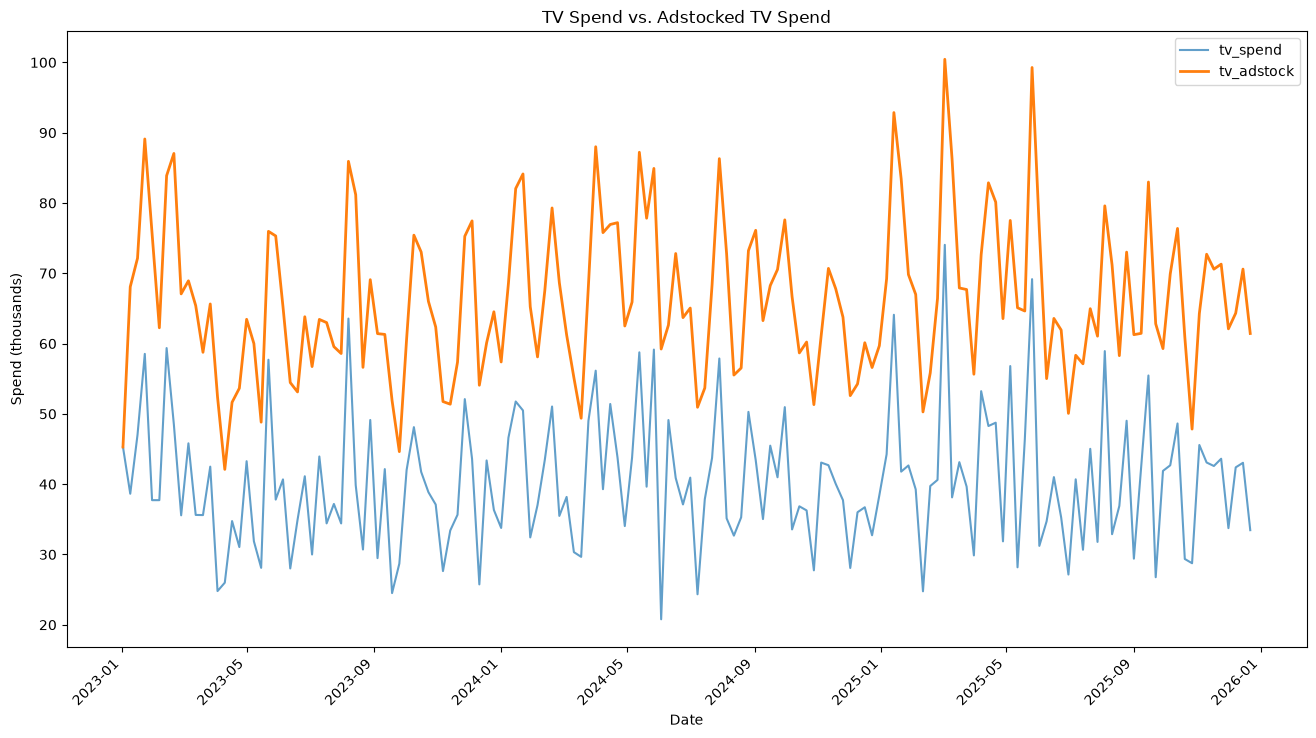

In [33]:
plt.figure(figsize=(16, 8))

plt.plot(df_clean['date'], df_clean['tv_spend'] / 1000.0, label='tv_spend', alpha=0.7)
plt.plot(df_clean['date'], df_clean['tv_adstock'], label='tv_adstock', linewidth=2)

plt.title("TV Spend vs. Adstocked TV Spend")
plt.xlabel("Date")
plt.ylabel("Spend (thousands)")
plt.legend()
plt.xticks(rotation=45, ha="right")
plt.show()

### Try against multiple levels of alpha

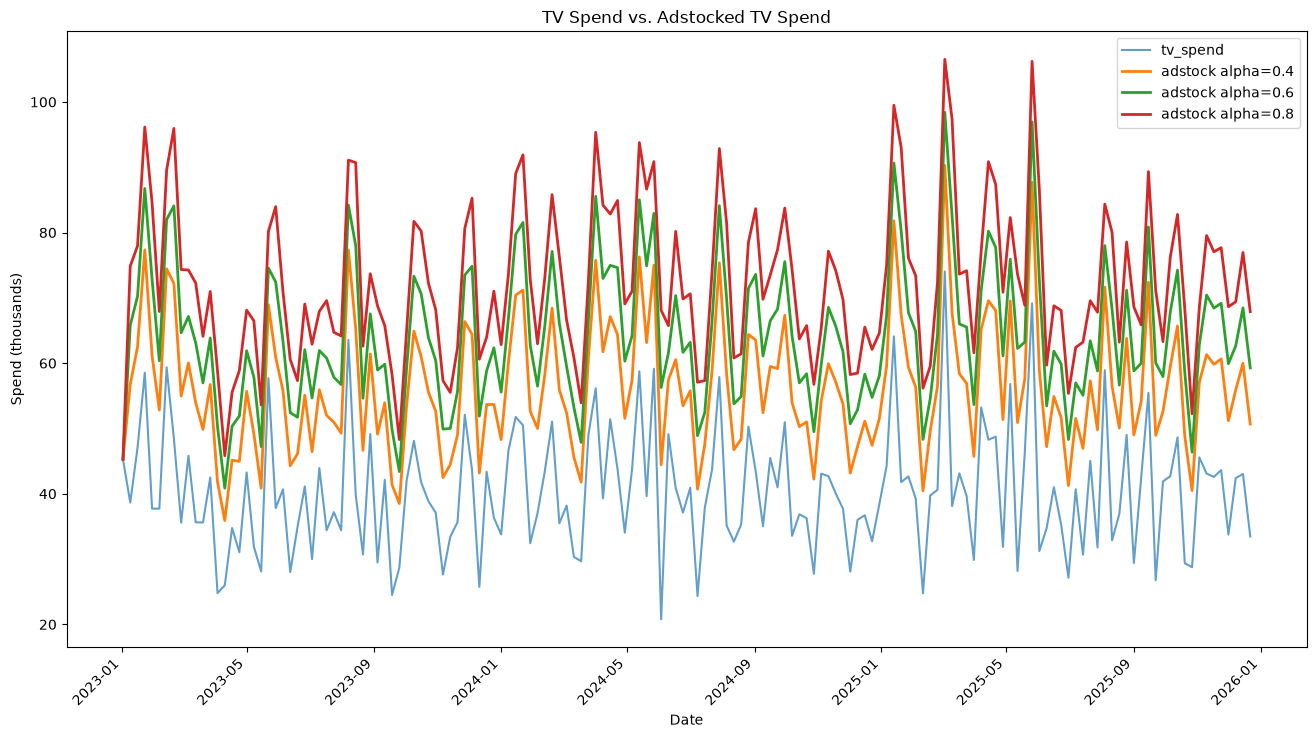

In [36]:
plt.figure(figsize=(16, 8))

plt.plot(df_clean['date'], df_clean['tv_spend'] / 1000.0, label='tv_spend', alpha=0.7)
plt.plot(df_clean['date'], geometric_adstock(df_clean['tv_spend'] / 1000.0, 0.4), label='adstock alpha=0.4', linewidth=2)
plt.plot(df_clean['date'], geometric_adstock(df_clean['tv_spend'] / 1000.0, 0.6), label='adstock alpha=0.6', linewidth=2)
plt.plot(df_clean['date'], geometric_adstock(df_clean['tv_spend'] / 1000.0, 0.8), label='adstock alpha=0.8', linewidth=2)

plt.title("TV Spend vs. Adstocked TV Spend")
plt.xlabel("Date")
plt.ylabel("Spend (thousands)")
plt.legend()
plt.xticks(rotation=45, ha="right")
plt.show()

### Knowledge checkpoint
Answer these three questions in your own words:

**1. If alpha increases from 0.3 to 0.8, what happens to advertising carryover and why?**

Advertising carryover from the previous week increases from 30% to 80%. Alpha represents the % of carryover to the current weekfrom the prior week's adstock.

**2. If two channels have identical weekly spending but different alpha values, will their adstocked spend be identical? Explain.**

No, because the channel with the higher alpha will have higher retention of the prior week's adstock into the current week.

**3. Why might TV advertising have a higher adstock parameter than paid search?**

A few reasons we might assign this:
* TV advertising is more memorable, so the effects of TV advertising are more likely to persist into the current week.
* TV advertising spend covers a longer period of time, so that last week's spend could still be impacting the frequency of this week's ads (where as paid search is typically spend at the click-level -  more synchronous ad spend to impact)

### Sidenote: Beta

Beta ($\beta$) represents the channel effect coefficient, specifically the immediate effect of a marketing channel on revenue.

In a typical Bayesian Marketing Mix Model (MMM):
- Alpha ($\alpha$) controls the carryover effect (adstock): how much of the previous period's advertising effect remains.
- Beta ($\beta$) measures the channel's contribution to revenue: how strongly the transformed channel activity affects the outcome.
For example, a simplified model might look like:

$$
Revenue_t = \beta \cdot Adstock_t + \epsilon_t
$$

Here, $\beta$ is the channel effect coefficient, while $Adstock_t$ represents advertising activity after accounting for carryover.

One important distinction: Beta is not necessarily the channel's total revenue contribution. That also depends on advertising spend, activity levels, transformations, and the model specification.

# Saturation and the Hill function

For our initial model, we'll use the simple Hill function with shape parameter fixed at 1:
$$
S(x)=\frac{x}{x+EC50}
$$

Where:
- $x$ = adstocked spend.
- $EC50$ = adstocked spend at which saturation reaches 50%.
- $S(x)$ = saturation between 0 and 1.
The actual channel contribution is then:
$$
Contribution = \beta \times S(x)
$$

Remember our earlier discussion: EC50 controls the horizontal position of the saturation curve, while beta controls its maximum contribution scale.

# Implement the Hill saturation function

In [37]:
def hill_saturation(x, ec50):
    """
    Apply a Hill saturation transformation.

    Parameters
    ----------
    x : array-like
        Adstocked marketing spend.
    ec50 : float
        Spend level at which saturation reaches 50%.

    Returns
    -------
    np.ndarray
        Saturation values between 0 and 1.
    """
    x = np.asarray(x, dtype=float)

    return x / (x + ec50)

In [41]:
## Apply saturation functino to TV adstock
df_clean["tv_saturation"] = hill_saturation(
    df["tv_adstock"],
    ec50=180
)

df_clean[["date", "tv_adstock", "tv_saturation"]].head(10)

,date,tv_adstock,tv_saturation
0,2023-01-02,45.288720,0.201025
1,2023-01-09,68.078648,0.274424
2,2023-01-16,72.147385,0.286132
3,2023-01-23,89.105691,0.331118
4,2023-01-30,75.773892,0.296253
5,2023-02-06,62.247532,0.256958
6,2023-02-13,83.885479,0.317886
7,2023-02-20,87.046367,0.325960
8,2023-02-27,67.069276,0.271459
9,2023-03-06,68.931473,0.276909


In [46]:
adstock_decay_values = {
    'tv': 0.65,
    'search': 0.25,
    'social': 0.45,
    'display': 0.35
}

for channel, alpha in adstock_decay_values.items():
    df_clean[f"{channel}_adstock"] = geometric_adstock(df_clean[f"{channel}_spend"].values / 1000.0, alpha=alpha)

In [48]:
ec50_values = {
    "tv": 180,
    "search": 35,
    "social": 65,
    "display": 30
}

for channel, ec50 in ec50_values.items():
    df_clean[f"{channel}_saturation"] = hill_saturation(
        df_clean[f"{channel}_adstock"],
        ec50=ec50
    )

### Plot all four saturation series over time.

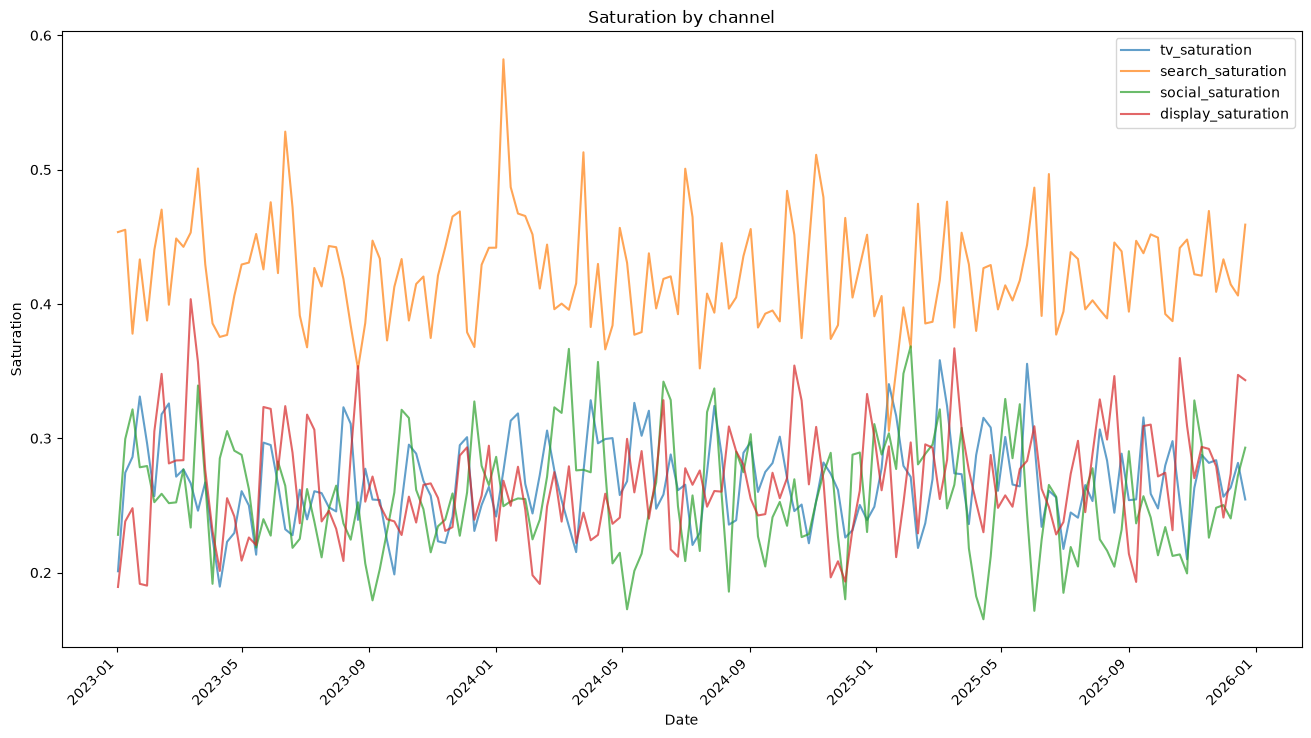

In [51]:
plt.figure(figsize=(16, 8))

for channel in ['tv', 'search', 'social', 'display']:
    plt.plot(df_clean['date'], df_clean[f"{channel}_saturation"], label=f"{channel}_saturation", alpha=0.7)

plt.title("Saturation by channel")
plt.xlabel("Date")
plt.ylabel("Saturation")
plt.legend()
plt.xticks(rotation=45, ha="right")
plt.show()

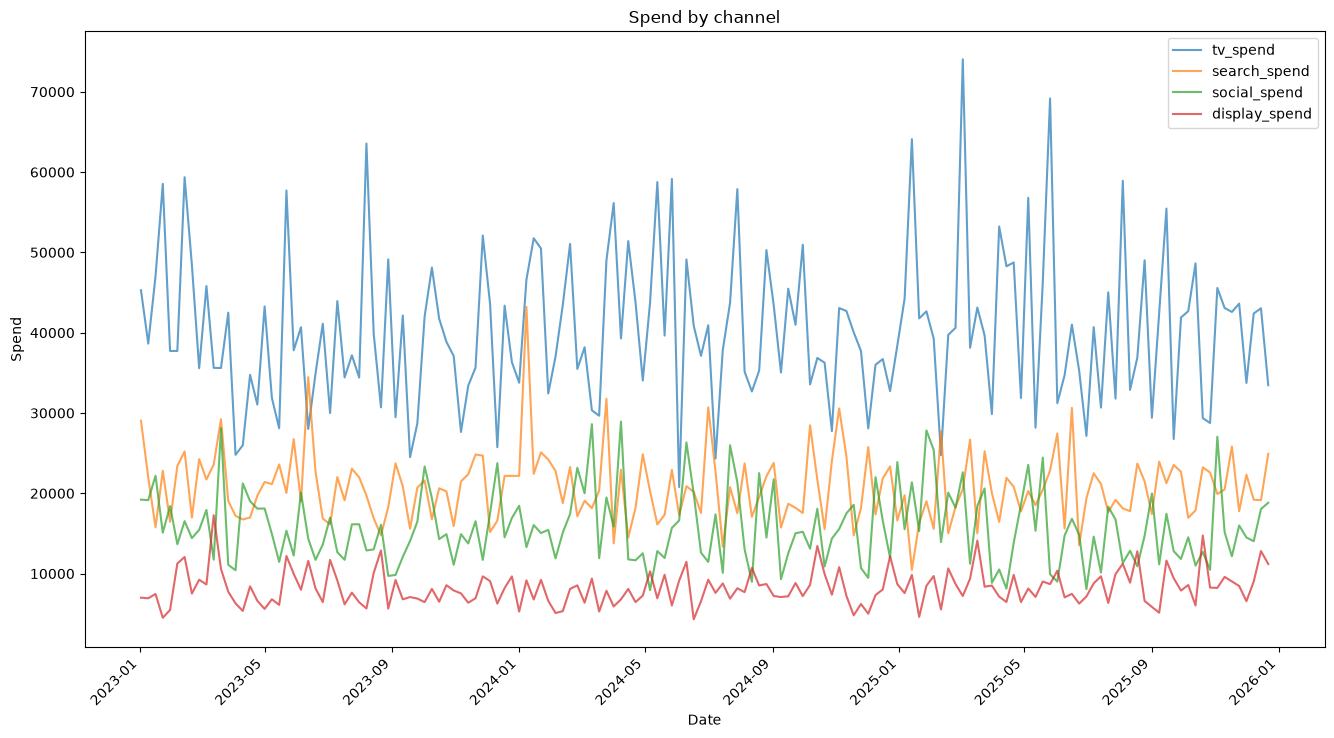

In [52]:
plt.figure(figsize=(16, 8))

for channel in ['tv', 'search', 'social', 'display']:
    plt.plot(df_clean['date'], df_clean[f"{channel}_spend"], label=f"{channel}_spend", alpha=0.7)

plt.title("Spend by channel")
plt.xlabel("Date")
plt.ylabel("Spend")
plt.legend()
plt.xticks(rotation=45, ha="right")
plt.show()

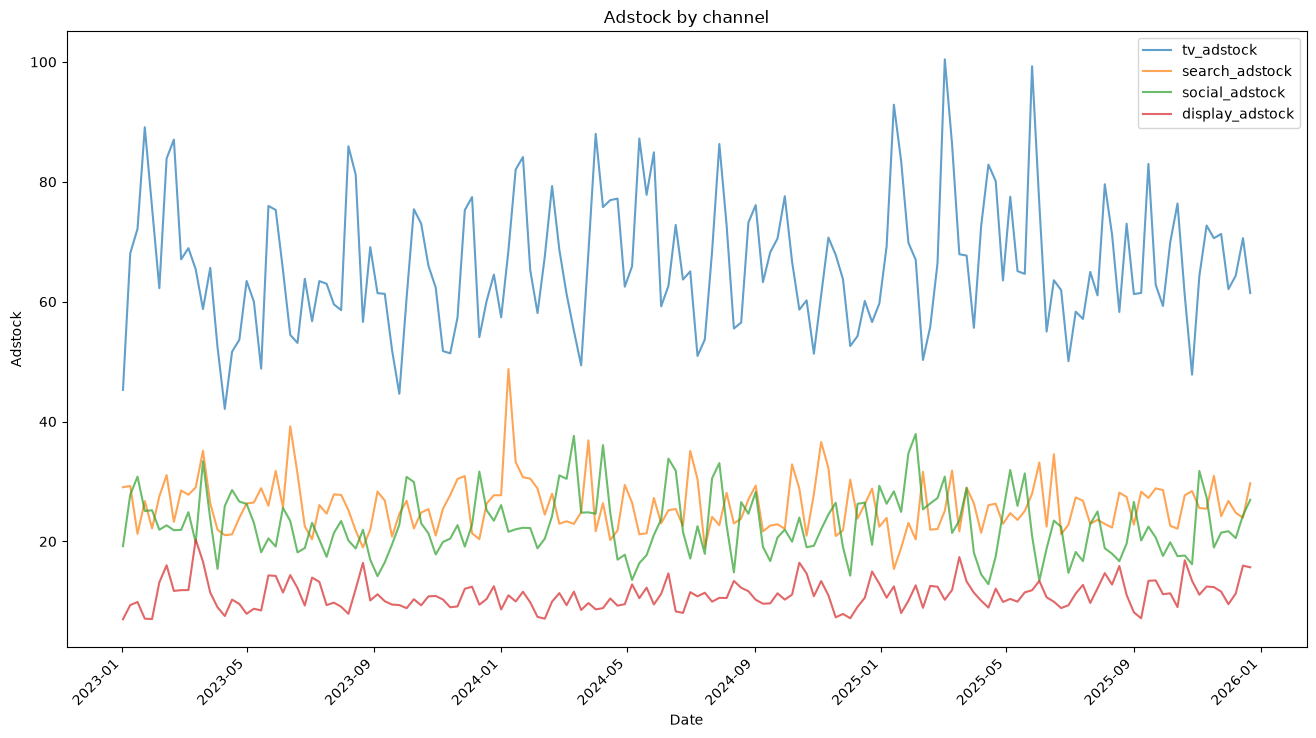

In [53]:
plt.figure(figsize=(16, 8))

for channel in ['tv', 'search', 'social', 'display']:
    plt.plot(df_clean['date'], df_clean[f"{channel}_adstock"], label=f"{channel}_adstock", alpha=0.7)

plt.title("Adstock by channel")
plt.xlabel("Date")
plt.ylabel("Adstock")
plt.legend()
plt.xticks(rotation=45, ha="right")
plt.show()